# MPC no lineal sobre la planta del péndulo

Primer paso del eje A: un MPC en CasADi con el modelo no lineal del env, integrado con RK4 a `dt = 0,02` y resuelto con Ipopt con warm start.

- La planta es `simulador/pendulo_env.py` (`PenduloGazebo-v0`), la misma del notebook `planta_pendulo.ipynb`.
- El MPC es `simulador/mpc_no_lineal.py`, con la misma estructura que `mpc.py` del nodo de ROS 2 (problema armado una vez con `ca.Opti`, `solve(estado)` que actualiza el parámetro y devuelve la primera acción, warm start desplazando la solución anterior).
- Costo de etapa $\ell(x, F) = x^\top Q x + R F^2$, igual al del env. Restricciones $|F| \le F_{max}$ dura y $|x| \le 0{,}5$ blanda con holgura penalizada.
- El costo terminal $V_f(x_N)$ es una función que se enchufa. Acá se prueban sin costo terminal y con $x^\top P x$ de Riccati.

In [1]:
%pip install -q "gymnasium[classic-control]" casadi scipy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\USUARIO\eje-a-mpc-pendulo\.venv\Scripts\python.exe -m pip install --upgrade pip


## Creación del env

In [2]:
import sys
sys.path.insert(0, "simulador")

import time
import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML

import pendulo_env  # registra "PenduloGazebo-v0"
from mpc_no_lineal import MPCNoLineal, paso_rk4, riccati, costo_terminal_cuadratico

env = gym.make("PenduloGazebo-v0", render_mode="rgb_array")
p = env.unwrapped.p

print(env.observation_space)
print(env.action_space)
print(f"dt = {p.dt} s, F_max = {p.fuerza_max} N, x_max = {p.x_max} m, Q = {np.diag(p.Q)}, R = {p.R}")

Box([-1.                -inf -3.14159265        -inf], [1.                inf 3.14159265        inf], (4,), float64)
Box(-100.0, 100.0, (1,), float32)
dt = 0.02 s, F_max = 100.0 N, x_max = 0.5 m, Q = [ 10.   1. 100.   1.], R = 0.1


## El modelo de predicción

`paso_rk4` arma $x_{k+1} = \mathrm{RK4}(x_k, F_k)$ con `derivada(..., lib=casadi)`, o sea la misma dinámica que el env. La única diferencia con la planta es el integrador (RK4 a 20 ms contra Euler semi implícito a 1 ms). Se compara la predicción a lazo abierto de 1 s con una secuencia de fuerzas cualquiera.

In [3]:
f_rk4 = paso_rk4(p, p.dt)
rng = np.random.default_rng(0)
fuerzas_prueba = rng.uniform(-5, 5, size=50)

estado, _ = env.reset(options={"estado": [0, 0, np.deg2rad(5), 0]})
x_pred = estado.copy()
errores = []
for F in fuerzas_prueba:
    estado, *_ = env.step([F])
    x_pred = np.array(f_rk4(x_pred, F)).ravel()
    errores.append(np.abs(x_pred - estado))
errores = np.array(errores)
print("error máximo en 1 s [x, x_d, th, th_d]:", errores.max(axis=0).round(5))

error máximo en 1 s [x, x_d, th, th_d]: [0.00161 0.00573 0.0064  0.0056 ]


## Riccati para el costo terminal

Se linealiza el modelo en el equilibrio con CasADi, se discretiza con retención de orden cero y se resuelve la DARE. $K$ sirve además como referencia (LQR).

In [4]:
P, K = riccati(p)
print("P =\n", P.round(1))
print("K =", K.round(2))
politica_lqr = lambda estado: -K @ estado

P =
 [[ 686.1  438.9 1058.5  200.8]
 [ 438.9  490.4 1241.   237.5]
 [1058.5 1241.  6826.5 1093.8]
 [ 200.8  237.5 1093.8  194.5]]
K = [[  -8.58  -11.78 -114.18  -19.28]]


## Herramientas

Mismas funciones que en `planta_pendulo.ipynb`, con dos agregados: `politica_mpc` envuelve al controlador (y reinicia el warm start al empezar cada episodio) y `resumen_tiempos` reporta medio, p95 y máximo del solve contra los 20 ms.

In [5]:
def politica_mpc(mpc):
    mpc.reiniciar()
    return lambda estado: np.array([mpc.solve(estado)])


def correr_episodio(env, politica, estado_inicial, renderizar=False, max_pasos=None):
    estado, _ = env.reset(options={"estado": estado_inicial})
    cuadros = [env.render()] if renderizar else []
    estados, fuerzas = [estado], []
    retorno, terminado = 0.0, False
    while not terminado:
        accion = politica(estado)
        estado, recompensa, terminated, truncated, info = env.step(accion)
        if renderizar:
            cuadros.append(env.render())
        estados.append(estado)
        fuerzas.append(info["fuerza"])
        retorno += recompensa
        terminado = terminated or truncated or (max_pasos is not None and len(fuerzas) >= max_pasos)
    print(f"{len(fuerzas)} pasos, retorno {retorno:.1f}, "
          f"fuera del riel {info['fuera_riel']}, caído {info['caido']}")
    return cuadros, np.array(estados), np.array(fuerzas)


def resumen_tiempos(mpc):
    t = 1e3 * np.array(mpc.tiempos_solve)
    print(f"solve: medio {t.mean():.1f} ms, p95 {np.percentile(t, 95):.1f} ms, "
          f"máx {t.max():.1f} ms, {np.mean(t > 1e3 * p.dt):.0%} arriba de {1e3 * p.dt:.0f} ms")
    return t


def animar(cuadros, estados, dt, cada=1):
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.axis("off")
    imagen = ax.imshow(cuadros[0])
    titulo = ax.set_title("")

    def actualizar(i):
        imagen.set_data(cuadros[i])
        titulo.set_text(f"t = {i * dt:.2f} s   θ = {np.rad2deg(estados[i, 2]):.1f}°   x = {estados[i, 0]:.2f} m")
        return [imagen, titulo]

    indices = range(0, len(cuadros), cada)
    anim = animation.FuncAnimation(fig, actualizar, frames=indices, interval=1000 * dt * cada)
    plt.close(fig)
    return HTML(anim.to_jshtml())


def graficar(corridas, dt):
    """corridas es un dict {etiqueta: (estados, fuerzas)} para superponer."""
    fig, ejes = plt.subplots(3, 1, figsize=(7, 6), sharex=True)
    for etiqueta, (estados, fuerzas) in corridas.items():
        t = np.arange(len(estados)) * dt
        ejes[0].plot(t, np.rad2deg(estados[:, 2]), label=etiqueta)
        ejes[1].plot(t, estados[:, 0])
        ejes[2].step(t[:-1], fuerzas, where="post")
    ejes[0].set_ylabel("θ [°]")
    ejes[0].legend()
    for signo in (1, -1):
        ejes[1].axhline(signo * p.x_max, color="gray", ls="--")
    ejes[1].set_ylabel("x [m]")
    ejes[2].set_ylabel("F [N]")
    ejes[2].set_xlabel("t [s]")
    plt.tight_layout()
    plt.show()

## Armado de los controladores

$N = 23$ como en `mpc_params.yaml`. El constructor hace un primer solve de calentamiento, porque la primera llamada a Ipopt arma el solver y tarda segundos.

In [6]:
N = 23
inicio = time.perf_counter()
mpc_sin_terminal = MPCNoLineal(p, N)
mpc_riccati = MPCNoLineal(p, N, costo_terminal=costo_terminal_cuadratico(P))
print(f"armado de los dos MPC: {time.perf_counter() - inicio:.1f} s")

armado de los dos MPC: 0.3 s


## Desde 15°

El LQR y el MPC con $x^\top P x$ lo estabilizan. Sin costo terminal, con $N = 23$ (0,46 s de horizonte) el MPC no ve que tiene que frenar el carro y lo pierde. Eso es justamente lo que el eje A quiere cuantificar.

500 pasos, retorno -494.4, fuera del riel False, caído False


51 pasos, retorno -1811.7, fuera del riel False, caído True


500 pasos, retorno -494.3, fuera del riel False, caído False
solve: medio 10.9 ms, p95 13.2 ms, máx 16.5 ms, 0% arriba de 20 ms


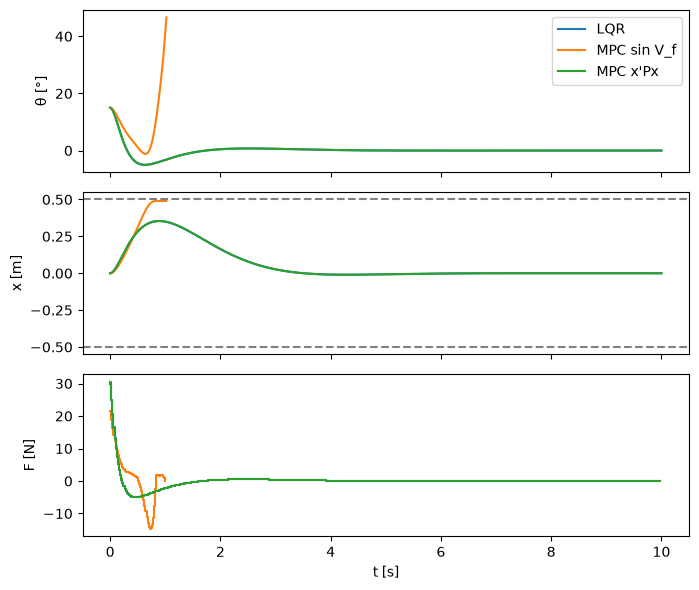

In [7]:
estado_inicial = [0, 0, np.deg2rad(15), 0]
corridas = {}
_, *corridas["LQR"] = correr_episodio(env, politica_lqr, estado_inicial)
_, *corridas["MPC sin V_f"] = correr_episodio(env, politica_mpc(mpc_sin_terminal), estado_inicial)
_, *corridas["MPC x'Px"] = correr_episodio(env, politica_mpc(mpc_riccati), estado_inicial)
resumen_tiempos(mpc_riccati)
graficar(corridas, p.dt)

## Desde 30°

El LQR se sale del riel (como en `planta_pendulo.ipynb`). El MPC con $x^\top P x$ usa la restricción del riel en la predicción y lo recupera.

20 pasos, retorno -2553.2, fuera del riel True, caído False


27 pasos, retorno -2994.5, fuera del riel False, caído True


500 pasos, retorno -3328.1, fuera del riel False, caído False
solve: medio 12.9 ms, p95 29.8 ms, máx 44.8 ms, 9% arriba de 20 ms


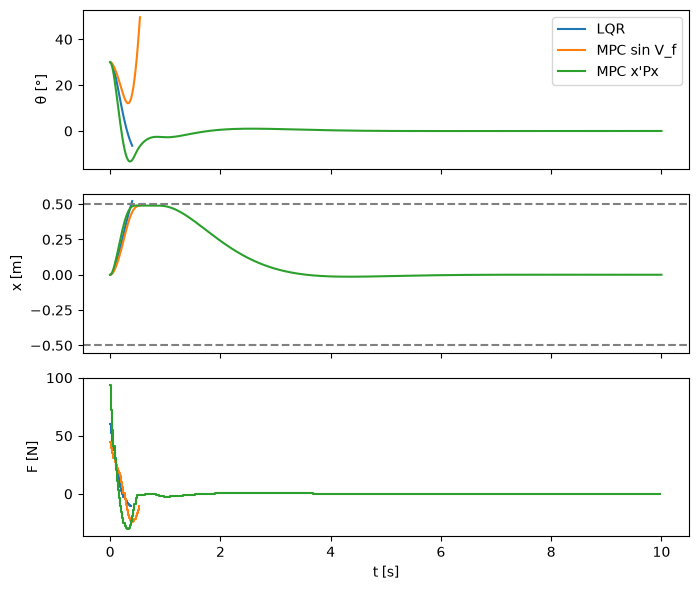

In [8]:
estado_inicial = [0, 0, np.deg2rad(30), 0]
corridas = {}
_, *corridas["LQR"] = correr_episodio(env, politica_lqr, estado_inicial)
_, *corridas["MPC sin V_f"] = correr_episodio(env, politica_mpc(mpc_sin_terminal), estado_inicial)
cuadros, *corridas["MPC x'Px"] = correr_episodio(env, politica_mpc(mpc_riccati), estado_inicial, renderizar=True)
tiempos_30 = resumen_tiempos(mpc_riccati)
graficar(corridas, p.dt)

In [9]:
animar(cuadros, corridas["MPC x'Px"][0], p.dt, cada=2)

## Referencia de horizonte largo

El plan usa como referencia un MPC con $N = 100$ (2 s) sin costo terminal. Acá se corre solo 3 s para ver que recupera los 30° y cuánto tarda el solve. No es un controlador implementable a 20 ms, es solo la referencia.

150 pasos, retorno -3309.8, fuera del riel False, caído False
solve: medio 47.0 ms, p95 119.5 ms, máx 136.5 ms, 100% arriba de 20 ms


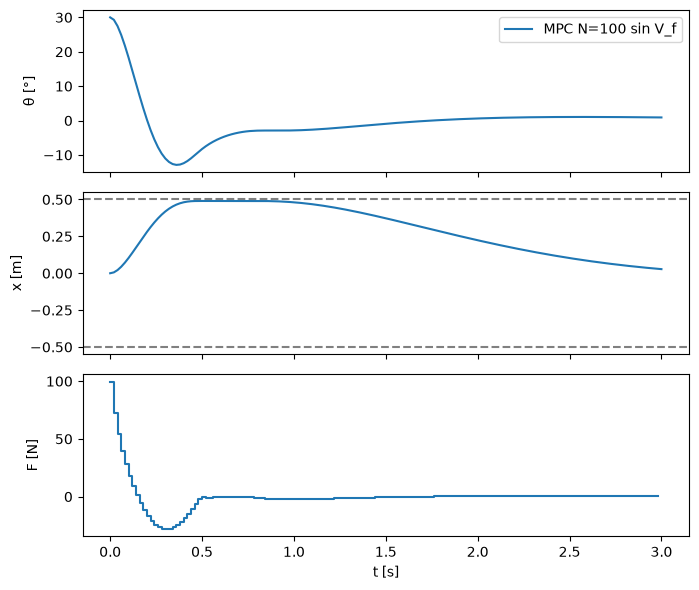

In [10]:
mpc_largo = MPCNoLineal(p, 100)
_, estados_largo, fuerzas_largo = correr_episodio(env, politica_mpc(mpc_largo), [0, 0, np.deg2rad(30), 0], max_pasos=150)
resumen_tiempos(mpc_largo)
graficar({"MPC N=100 sin V_f": (estados_largo, fuerzas_largo)}, p.dt)

## Con perturbación

Desde el equilibrio, un torque de 3 N m sobre la junta durante 50 ms a partir de t = 1 s (como `disturbance_test`). Con ese torque el LQR ya se salía del riel.

80 pasos, retorno -1833.6, fuera del riel True, caído False


200 pasos, retorno -1296.2, fuera del riel False, caído False


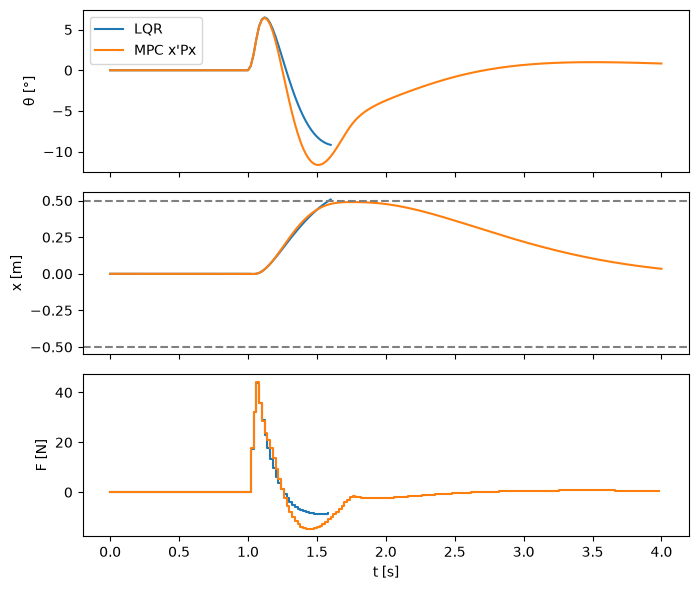

In [11]:
def con_perturbacion(politica, inicio=1.0, duracion=0.05, torque=3.0):
    contador = {"paso": 0}

    def politica_perturbada(estado):
        t = contador["paso"] * p.dt
        env.unwrapped.torque_perturbacion = torque if inicio <= t < inicio + duracion else 0.0
        contador["paso"] += 1
        return politica(estado)

    return politica_perturbada

corridas = {}
_, *corridas["LQR"] = correr_episodio(env, con_perturbacion(politica_lqr), [0, 0, 0, 0], max_pasos=200)
_, *corridas["MPC x'Px"] = correr_episodio(env, con_perturbacion(politica_mpc(mpc_riccati)), [0, 0, 0, 0], max_pasos=200)
graficar(corridas, p.dt)

## Tiempo de solve

Histograma de la corrida desde 30° con $x^\top P x$, que es la más exigente. El tiempo incluye el overhead de Python de `Opti` (set_value, set_initial), no solo Ipopt.

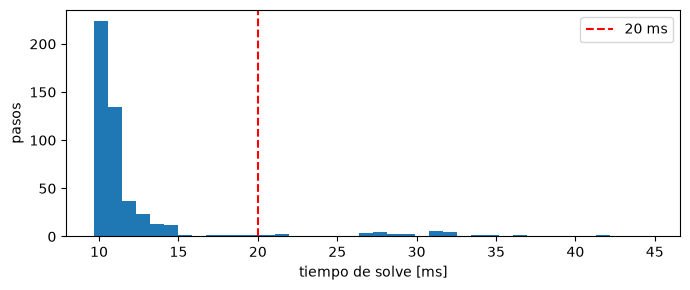

In [12]:
plt.figure(figsize=(7, 3))
plt.hist(tiempos_30, bins=40)
plt.axvline(1e3 * p.dt, color="red", ls="--", label="20 ms")
plt.xlabel("tiempo de solve [ms]")
plt.ylabel("pasos")
plt.legend()
plt.tight_layout()
plt.show()

## Pendientes

- **Elegir y justificar F_max.** Por ahora se usa el effort del URDF (100 N), y lo que limita es el riel. Bajar F_max hace que la saturación también importe. Se cambia con `MPCNoLineal(p, N, F_max=...)`.
- **Tiempo de solve.** Si el p95 o el máximo pasan de 20 ms, las opciones son pasar de `Opti` a `nlpsol` directo (menos overhead de Python), compilar con `jit` o usar SQP con un QP (`sqpmethod` + `qrqp`/`osqp`).
- **Contraparte clásica.** $x_N \in \Omega$ ya está soportado con `conjunto_terminal=(P, alpha)`; falta calcular $\alpha$.
- **Script de la región de recuperación** (grilla 30×30 en $(\theta_0, \dot x_0)$).